In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score


In [ ]:
MODEL_OUTPUT_DIR = "/content/drive/MyDrive/Wheat_Output"
TEST_DIR = "/content/drive/MyDrive/Wheat_Final/test"

CLASS_NAMES = [
    "Crown and Root Rot",
    "Healthy Wheat",
    "Leaf Rust",
    "Septoria",
    "Stripe Rust"
]
NUM_CLASSES = len(CLASS_NAMES)


# MobileNetV2

In [ ]:
model_name = "mobilenetv2"

In [ ]:
# ==============================
# 8️⃣ Inference helper
# ==============================

from PIL import Image, ImageOps
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.models import load_model


def preprocess_input_image(image_path):
    """
    Image preprocessing MUST match training pipeline.
    Model-specific preprocess_input is already INSIDE the model (Lambda layer).
    """
    img = Image.open(image_path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")

    w, h = img.size
    m = min(w, h)
    img = img.crop(((w - m)//2, (h - m)//2, (w + m)//2, (h + m)//2))
    img = img.resize((224, 224), Image.Resampling.LANCZOS)

    return np.array(img).astype(np.float32)


# ==============================
# 9️⃣ Load model correctly
# ==============================


model_name_lower = model_name.lower()

if "efficientnetb0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet import preprocess_input
elif "efficientnetv2b0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
elif "mobilenetv2" in model_name_lower:
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
elif "resnet50" in model_name_lower:
    from tensorflow.keras.applications.resnet import preprocess_input
else:
    raise ValueError("Unknown model name")

# custom_objects = {"preprocess_input": preprocess_input}

# model_path = os.path.join(
#     MODEL_OUTPUT_DIR,
#     f"{model_name_lower}_balanced_500.h5"
# )

# print("Loading model from:", model_path)

# model_loaded = load_model(
#     model_path,
#     custom_objects=custom_objects,
#     compile=False
# )

# print("✅ Model loaded successfully")

model_path = "/content/drive/MyDrive/Wheat_Output/mobilenetv2_balanced_500.h5"

model_loaded = load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("✅ MobileNetV2 model loaded successfully")




✅ MobileNetV2 model loaded successfully


In [ ]:

# ==============================
# 🔍 Single image sanity check
# ==============================

# sample_class = CLASS_NAMES[0]
# sample_img = os.listdir(os.path.join(TEST_DIR, sample_class))[0]
# sample_path = os.path.join(TEST_DIR, sample_class, sample_img)

sample_path = "/content/drive/MyDrive/Wheat_Final/test/Healthy Wheat/05291.jpg"


img_arr = preprocess_input_image(sample_path)
pred = model_loaded.predict(np.expand_dims(img_arr, 0), verbose=0)
pred_class = np.argmax(pred, axis=1)[0]

# print("True class:", sample_class)
# sample_path = "/content/drive/MyDrive/Wheat_Images/Septoria/Septoria1886.png"
print("Image path:", sample_path)
print("Predicted class:", CLASS_NAMES[pred_class])



Image path: /content/drive/MyDrive/Wheat_Final/test/Healthy Wheat/05291.jpg
Predicted class: Healthy Wheat



Test Accuracy: 88.4 %

Classification Report:
                    precision    recall  f1-score   support

Crown and Root Rot       0.93      0.82      0.87        50
     Healthy Wheat       0.84      0.84      0.84        50
         Leaf Rust       0.81      0.86      0.83        50
          Septoria       0.90      0.92      0.91        50
       Stripe Rust       0.94      0.98      0.96        50

          accuracy                           0.88       250
         macro avg       0.89      0.88      0.88       250
      weighted avg       0.89      0.88      0.88       250



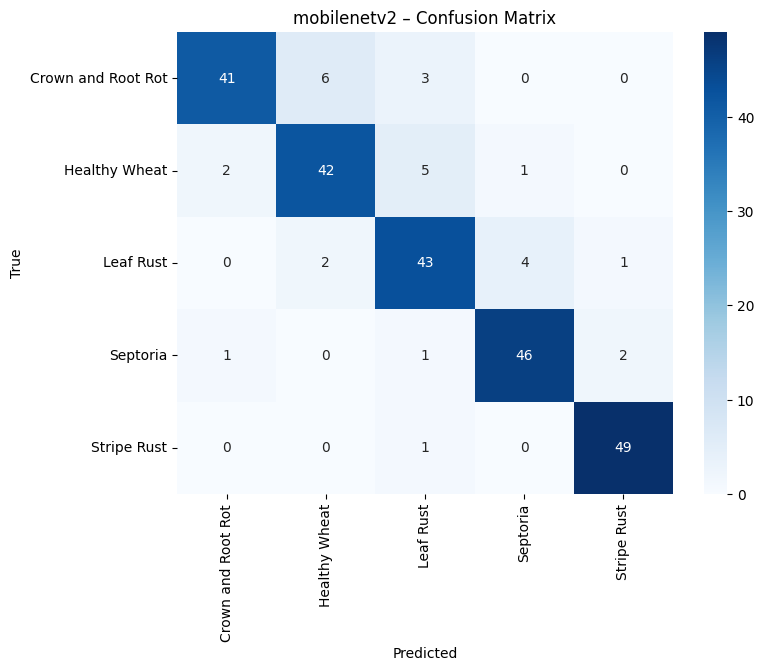

In [ ]:

# ==============================
# 🔢 10️⃣ Full Evaluation
# ==============================

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR, cls_name)
    for fname in os.listdir(cls_dir):
        img_path = os.path.join(cls_dir, fname)
        img = preprocess_input_image(img_path)

        preds = model_loaded.predict(
            np.expand_dims(img, 0),
            verbose=0
        )
        y_pred.append(np.argmax(preds))
        y_true.append(cls_idx)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Accuracy
acc = accuracy_score(y_true, y_pred)
print("\n==============================")
print("Test Accuracy:", round(acc * 100, 2), "%")
print("==============================\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"{model_name} – Confusion Matrix")
plt.show()


# ResNet50

In [ ]:
model_name = "resnet50"


In [ ]:
# ==============================
# 8️⃣ Inference helper
# ==============================

from PIL import Image, ImageOps
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.models import load_model


def preprocess_input_image(image_path):
    """
    Image preprocessing MUST match training pipeline.
    Model-specific preprocess_input is already INSIDE the model (Lambda layer).
    """
    img = Image.open(image_path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")

    w, h = img.size
    m = min(w, h)
    img = img.crop(((w - m)//2, (h - m)//2, (w + m)//2, (h + m)//2))
    img = img.resize((224, 224), Image.Resampling.LANCZOS)

    return np.array(img).astype(np.float32)


# ==============================
# 9️⃣ Load model correctly
# ==============================


model_name_lower = model_name.lower()

if "efficientnetb0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet import preprocess_input
elif "efficientnetv2b0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
elif "mobilenetv2" in model_name_lower:
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
elif "resnet50" in model_name_lower:
    from tensorflow.keras.applications.resnet import preprocess_input
else:
    raise ValueError("Unknown model name")

# custom_objects = {"preprocess_input": preprocess_input}

# model_path = os.path.join(
#     MODEL_OUTPUT_DIR,
#     f"{model_name_lower}_balanced_500.h5"
# )

# print("Loading model from:", model_path)

# model_loaded = load_model(
#     model_path,
#     custom_objects=custom_objects,
#     compile=False
# )

# print("✅ Model loaded successfully")

model_path = "/content/drive/MyDrive/Wheat_Output/resnet50_balanced_500.h5"

model_loaded = load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("✅ ResNet50 model loaded successfully")




✅ ResNet50 model loaded successfully


In [ ]:

# ==============================
# 🔍 Single image sanity check
# ==============================

# sample_class = CLASS_NAMES[0]
# sample_img = os.listdir(os.path.join(TEST_DIR, sample_class))[0]
# sample_path = os.path.join(TEST_DIR, sample_class, sample_img)

sample_path = "/content/drive/MyDrive/Wheat_Final/test/Stripe Rust/lolr(200).JPG"


img_arr = preprocess_input_image(sample_path)
pred = model_loaded.predict(np.expand_dims(img_arr, 0), verbose=0)
pred_class = np.argmax(pred, axis=1)[0]

# print("True class:", sample_class)
# sample_path = "/content/drive/MyDrive/Wheat_Images/Septoria/Septoria1886.png"
print("Image path:", sample_path)
print("Predicted class:", CLASS_NAMES[pred_class])



Image path: /content/drive/MyDrive/Wheat_Final/test/Stripe Rust/lolr(200).JPG
Predicted class: Stripe Rust



Test Accuracy: 91.6 %

Classification Report:
                    precision    recall  f1-score   support

Crown and Root Rot       0.90      0.92      0.91        50
     Healthy Wheat       0.87      0.82      0.85        50
         Leaf Rust       0.90      0.88      0.89        50
          Septoria       0.93      1.00      0.96        50
       Stripe Rust       0.98      0.96      0.97        50

          accuracy                           0.92       250
         macro avg       0.92      0.92      0.92       250
      weighted avg       0.92      0.92      0.92       250



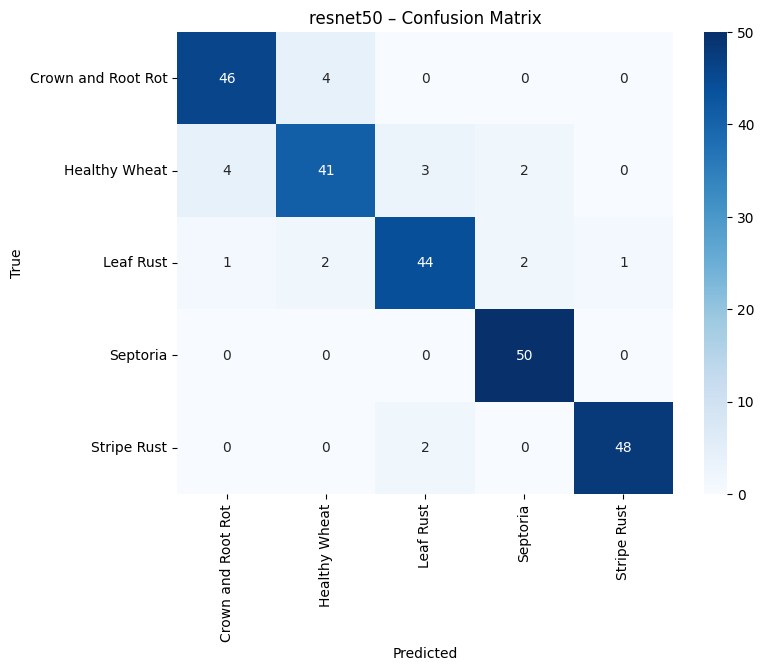

In [ ]:

# ==============================
# 🔢 10️⃣ Full Evaluation
# ==============================

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR, cls_name)
    for fname in os.listdir(cls_dir):
        img_path = os.path.join(cls_dir, fname)
        img = preprocess_input_image(img_path)

        preds = model_loaded.predict(
            np.expand_dims(img, 0),
            verbose=0
        )
        y_pred.append(np.argmax(preds))
        y_true.append(cls_idx)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Accuracy
acc = accuracy_score(y_true, y_pred)
print("\n==============================")
print("Test Accuracy:", round(acc * 100, 2), "%")
print("==============================\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"{model_name} – Confusion Matrix")
plt.show()


In [ ]:
import tensorflow as tf
import numpy as np

def tta_augmentations(image):
    """
    image: (224,224,3) float32 image (NOT preprocessed)
    returns: list of augmented images
    """
    aug_images = []

    # original
    aug_images.append(image)

    # horizontal flip
    aug_images.append(tf.image.flip_left_right(image))

    # brightness variations
    aug_images.append(tf.image.adjust_brightness(image, delta=0.05))
    aug_images.append(tf.image.adjust_brightness(image, delta=-0.05))

    # contrast variations
    aug_images.append(tf.image.adjust_contrast(image, 1.1))
    aug_images.append(tf.image.adjust_contrast(image, 0.9))

    # slight crop + resize
    crop = tf.image.central_crop(image, central_fraction=0.9)
    crop = tf.image.resize(crop, (224,224))
    aug_images.append(crop)

    return aug_images


In [ ]:
def predict_with_tta(model, image_array):
    """
    model: trained keras model
    image_array: (224,224,3) float32 image
    """
    aug_images = tta_augmentations(image_array)

    preds = []
    for img in aug_images:
        img_batch = tf.expand_dims(img, axis=0)  # (1,224,224,3)
        pred = model.predict(img_batch, verbose=0)
        preds.append(pred)

    preds = np.vstack(preds)        # (N, num_classes)
    mean_pred = np.mean(preds, axis=0)

    return mean_pred


In [ ]:
def evaluate_with_tta(model, test_dataset, class_names):
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
    import matplotlib.pyplot as plt
    import seaborn as sns

    y_true = []
    y_pred = []

    for images, labels in test_dataset:
        images = images.numpy()
        labels = labels.numpy()

        for img, lbl in zip(images, labels):
            pred = predict_with_tta(model, img)
            y_pred.append(np.argmax(pred))
            y_true.append(lbl)

    acc = accuracy_score(y_true, y_pred)
    print("\n==============================")
    print("TTA Test Accuracy:", round(acc * 100, 2), "%")
    print("==============================\n")

    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (TTA)")
    plt.show()


In [ ]:
model_loaded = "resnet50"


✅ ResNet50 model reloaded successfully for TTA

TTA Test Accuracy: 92.0 %

Classification Report:
                    precision    recall  f1-score   support

Crown and Root Rot       0.90      0.94      0.92        50
     Healthy Wheat       0.89      0.82      0.85        50
         Leaf Rust       0.90      0.88      0.89        50
          Septoria       0.93      1.00      0.96        50
       Stripe Rust       0.98      0.96      0.97        50

          accuracy                           0.92       250
         macro avg       0.92      0.92      0.92       250
      weighted avg       0.92      0.92      0.92       250



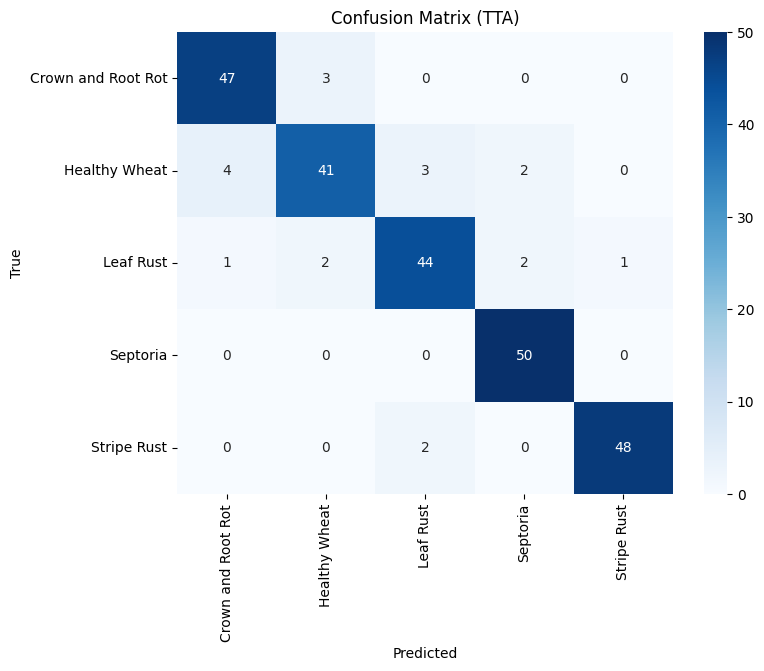

In [ ]:
import tensorflow as tf
import os
from PIL import Image, ImageOps
import numpy as np

# --- Inference helper function (copied for scope) ---
def preprocess_input_image(image_path):
    """
    Image preprocessing MUST match training pipeline.
    Model-specific preprocess_input is already INSIDE the model (Lambda layer).
    """
    img = Image.open(image_path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")

    w, h = img.size
    m = min(w, h)
    img = img.crop(((w - m)//2, (h - m)//2, (w + m)//2, (h + m)//2))
    img = img.resize((224, 224), Image.Resampling.LANCZOS)

    return np.array(img).astype(np.float32)

# --- Reload the ResNet50 model (because `model_loaded` is currently a string) ---
# This part ensures `model_loaded_actual_keras` holds the actual Keras model
model_name = "resnet50"  # Ensure model_name is set correctly for preprocess_input import
model_name_lower = model_name.lower()

if "resnet50" in model_name_lower:
    from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess_input
else:
    raise ValueError("Unknown model name for TTA evaluation")

model_path_resnet = os.path.join(MODEL_OUTPUT_DIR, "resnet50_balanced_500.h5")

model_loaded_actual_keras = tf.keras.models.load_model(
    model_path_resnet,
    custom_objects={"preprocess_input": resnet_preprocess_input},
    compile=False
)
print("✅ ResNet50 model reloaded successfully for TTA")

# --- Prepare image paths and labels from TEST_DIR ---
all_image_paths = []
all_image_labels = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR, cls_name)
    for fname in os.listdir(cls_dir):
        img_path = os.path.join(cls_dir, fname)
        all_image_paths.append(img_path)
        all_image_labels.append(cls_idx)

# --- Create a tf.data.Dataset ---
dataset = tf.data.Dataset.from_tensor_slices((all_image_paths, all_image_labels))

# --- Map preprocessing function ---
def load_and_preprocess_image_py_function(image_path_tensor, label_tensor):
    # Convert tensor path to string
    image_path = image_path_tensor.numpy().decode('utf-8')
    # Use the existing preprocess_input_image (PIL, numpy based) that returns 0-255 float32
    img_array = preprocess_input_image(image_path)
    return tf.convert_to_tensor(img_array, dtype=tf.float32), label_tensor

def tf_dataset_preprocess(image_path_tensor, label_tensor):
    img, lbl = tf.py_function(
        load_and_preprocess_image_py_function,
        [image_path_tensor, label_tensor],
        [tf.float32, tf.int32]
    )
    img.set_shape([224, 224, 3]) # Set shape for consistency
    lbl.set_shape([]) # Set scalar shape for label
    return img, lbl

dataset = dataset.map(tf_dataset_preprocess, num_parallel_calls=tf.data.AUTOTUNE)

# --- Batch the dataset ---
# evaluate_with_tta expects (batch_images, batch_labels) for its loop structure
BATCH_SIZE = 32
dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# --- Call evaluate_with_tta with the reloaded model and the new dataset ---
evaluate_with_tta(model_loaded_actual_keras, dataset, CLASS_NAMES)

# EfficientNetB0

In [ ]:
model_name = "efficientnetb0"


In [ ]:
# ==============================
# 8️⃣ Inference helper
# ==============================

from PIL import Image, ImageOps
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.models import load_model


def preprocess_input_image(image_path):
    """
    Image preprocessing MUST match training pipeline.
    Model-specific preprocess_input is already INSIDE the model (Lambda layer).
    """
    img = Image.open(image_path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")

    w, h = img.size
    m = min(w, h)
    img = img.crop(((w - m)//2, (h - m)//2, (w + m)//2, (h + m)//2))
    img = img.resize((224, 224), Image.Resampling.LANCZOS)

    return np.array(img).astype(np.float32)


# ==============================
# 9️⃣ Load model correctly
# ==============================


model_name_lower = model_name.lower()

if "efficientnetb0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet import preprocess_input
elif "efficientnetv2b0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
elif "mobilenetv2" in model_name_lower:
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
elif "resnet50" in model_name_lower:
    from tensorflow.keras.applications.resnet import preprocess_input
else:
    raise ValueError("Unknown model name")

# custom_objects = {"preprocess_input": preprocess_input}

# model_path = os.path.join(
#     MODEL_OUTPUT_DIR,
#     f"{model_name_lower}_balanced_500.h5"
# )

# print("Loading model from:", model_path)

# model_loaded = load_model(
#     model_path,
#     custom_objects=custom_objects,
#     compile=False
# )

# print("✅ Model loaded successfully")

model_path = "/content/drive/MyDrive/Wheat_Output/efficientnetb0_balanced_500.h5"

model_loaded = load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("✅ EfficientNetB0 model loaded successfully")




✅ EfficientNetB0 model loaded successfully


In [ ]:

# ==============================
# 🔍 Single image sanity check
# ==============================

# sample_class = CLASS_NAMES[0]
# sample_img = os.listdir(os.path.join(TEST_DIR, sample_class))[0]
# sample_path = os.path.join(TEST_DIR, sample_class, sample_img)

sample_path = "/content/drive/MyDrive/Wheat_Final/test/Septoria/Septoria3284.png"


img_arr = preprocess_input_image(sample_path)
pred = model_loaded.predict(np.expand_dims(img_arr, 0), verbose=0)
pred_class = np.argmax(pred, axis=1)[0]

# print("True class:", sample_class)
# sample_path = "/content/drive/MyDrive/Wheat_Images/Septoria/Septoria1886.png"
print("Image path:", sample_path)
print("Predicted class:", CLASS_NAMES[pred_class])



Image path: /content/drive/MyDrive/Wheat_Final/test/Septoria/Septoria3284.png
Predicted class: Septoria



Test Accuracy: 80.4 %

Classification Report:
                    precision    recall  f1-score   support

Crown and Root Rot       0.73      0.80      0.76        50
     Healthy Wheat       0.73      0.82      0.77        50
         Leaf Rust       0.72      0.68      0.70        50
          Septoria       0.96      0.90      0.93        50
       Stripe Rust       0.91      0.82      0.86        50

          accuracy                           0.80       250
         macro avg       0.81      0.80      0.81       250
      weighted avg       0.81      0.80      0.81       250



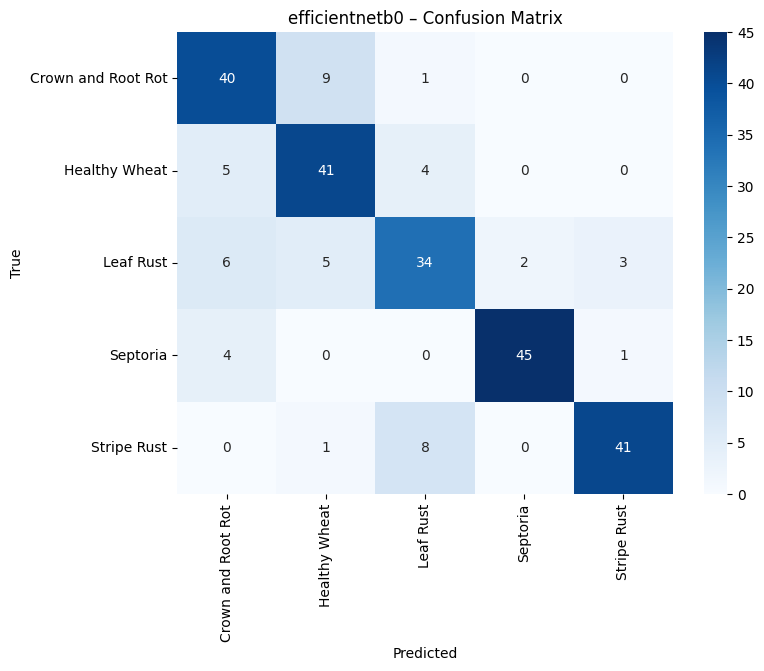

In [ ]:

# ==============================
# 🔢 10️⃣ Full Evaluation
# ==============================

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR, cls_name)
    for fname in os.listdir(cls_dir):
        img_path = os.path.join(cls_dir, fname)
        img = preprocess_input_image(img_path)

        preds = model_loaded.predict(
            np.expand_dims(img, 0),
            verbose=0
        )
        y_pred.append(np.argmax(preds))
        y_true.append(cls_idx)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Accuracy
acc = accuracy_score(y_true, y_pred)
print("\n==============================")
print("Test Accuracy:", round(acc * 100, 2), "%")
print("==============================\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"{model_name} – Confusion Matrix")
plt.show()


# EfficientNetV2B0

In [ ]:
model_name = "efficientnetv2b0"


In [ ]:
# ==============================
# 8️⃣ Inference helper
# ==============================

from PIL import Image, ImageOps
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.models import load_model


def preprocess_input_image(image_path):
    """
    Image preprocessing MUST match training pipeline.
    Model-specific preprocess_input is already INSIDE the model (Lambda layer).
    """
    img = Image.open(image_path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")

    w, h = img.size
    m = min(w, h)
    img = img.crop(((w - m)//2, (h - m)//2, (w + m)//2, (h + m)//2))
    img = img.resize((224, 224), Image.Resampling.LANCZOS)

    return np.array(img).astype(np.float32)


# ==============================
# 9️⃣ Load model correctly
# ==============================


model_name_lower = model_name.lower()

if "efficientnetb0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet import preprocess_input
elif "efficientnetv2b0" in model_name_lower:
    from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
elif "mobilenetv2" in model_name_lower:
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
elif "resnet50" in model_name_lower:
    from tensorflow.keras.applications.resnet import preprocess_input
else:
    raise ValueError("Unknown model name")

# custom_objects = {"preprocess_input": preprocess_input}

# model_path = os.path.join(
#     MODEL_OUTPUT_DIR,
#     f"{model_name_lower}_balanced_500.h5"
# )

# print("Loading model from:", model_path)

# model_loaded = load_model(
#     model_path,
#     custom_objects=custom_objects,
#     compile=False
# )

# print("✅ Model loaded successfully")

model_path = "/content/drive/MyDrive/Wheat_Output/efficientnetv2b0_balanced_500.h5"

model_loaded = load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("✅ EfficientNetV2B0 model loaded successfully")




✅ EfficientNetV2B0 model loaded successfully


In [ ]:

# ==============================
# 🔍 Single image sanity check
# ==============================

# sample_class = CLASS_NAMES[0]
# sample_img = os.listdir(os.path.join(TEST_DIR, sample_class))[0]
# sample_path = os.path.join(TEST_DIR, sample_class, sample_img)

sample_path = "/content/drive/MyDrive/Wheat_Final/test/Septoria/Septoria3284.png"


img_arr = preprocess_input_image(sample_path)
pred = model_loaded.predict(np.expand_dims(img_arr, 0), verbose=0)
pred_class = np.argmax(pred, axis=1)[0]

# print("True class:", sample_class)
# sample_path = "/content/drive/MyDrive/Wheat_Images/Septoria/Septoria1886.png"
print("Image path:", sample_path)
print("Predicted class:", CLASS_NAMES[pred_class])



Image path: /content/drive/MyDrive/Wheat_Final/test/Septoria/Septoria3284.png
Predicted class: Septoria



Test Accuracy: 91.2 %

Classification Report:
                    precision    recall  f1-score   support

Crown and Root Rot       0.88      0.90      0.89        50
     Healthy Wheat       0.87      0.82      0.85        50
         Leaf Rust       0.85      0.88      0.86        50
          Septoria       1.00      0.98      0.99        50
       Stripe Rust       0.96      0.98      0.97        50

          accuracy                           0.91       250
         macro avg       0.91      0.91      0.91       250
      weighted avg       0.91      0.91      0.91       250



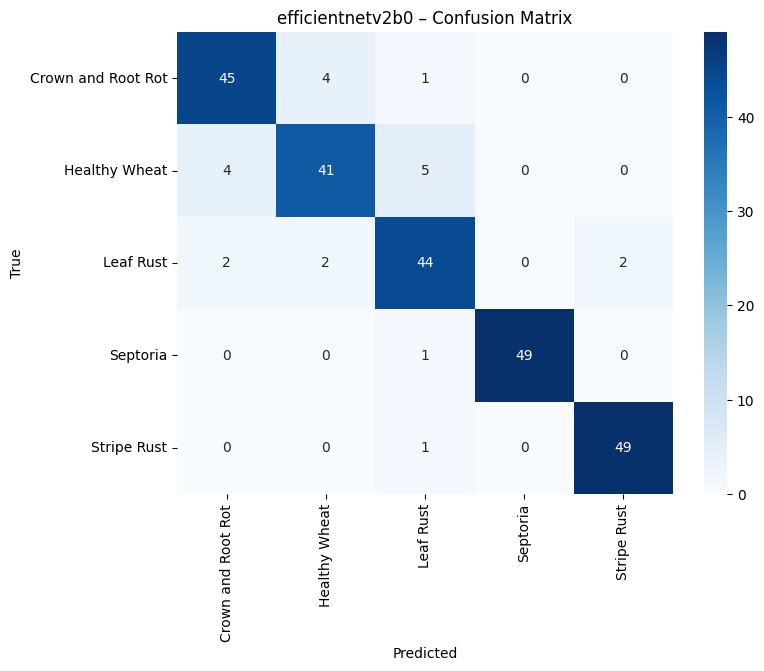

In [ ]:

# ==============================
# 🔢 10️⃣ Full Evaluation
# ==============================

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR, cls_name)
    for fname in os.listdir(cls_dir):
        img_path = os.path.join(cls_dir, fname)
        img = preprocess_input_image(img_path)

        preds = model_loaded.predict(
            np.expand_dims(img, 0),
            verbose=0
        )
        y_pred.append(np.argmax(preds))
        y_true.append(cls_idx)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Accuracy
acc = accuracy_score(y_true, y_pred)
print("\n==============================")
print("Test Accuracy:", round(acc * 100, 2), "%")
print("==============================\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"{model_name} – Confusion Matrix")
plt.show()


In [ ]:
from tensorflow.keras.models import load_model
import os
import tensorflow as tf

# Ensure MODEL_OUTPUT_DIR is defined, which it is in a previous cell.
model_path = os.path.join(MODEL_OUTPUT_DIR, "resnet50_balanced_500.h5")

model = load_model(
    model_path,
    compile=False,
    custom_objects={"preprocess_input": tf.keras.applications.resnet.preprocess_input}
)

print("✅ ResNet50 model loaded successfully from Drive.")
model.save("resnet50_balanced_500.keras")
print("✅ ResNet50 model saved to .keras format.")

✅ ResNet50 model loaded successfully from Drive.
✅ ResNet50 model saved to .keras format.
